# Inspección de crops
Ejecuta el extractor y muestra hasta diez crops con sus cajas en las imágenes fuente.

BrocadoLeve.jpg: 30 crops
BrocadoSevero.jpg: 25 crops
CerezaSeca.jpg: 9 crops
Concha.jpg: 33 crops
DXHongo.jpg: 12 crops
Inmaduro.jpg: 16 crops
MarronAVinagre.jpg: 36 crops
Negros.jpg: 100 crops
Normales.jpg: 195 crops
PMordidoCortado.jpg: 37 crops
Pergamino.jpg: 90 crops
Total crops: 583


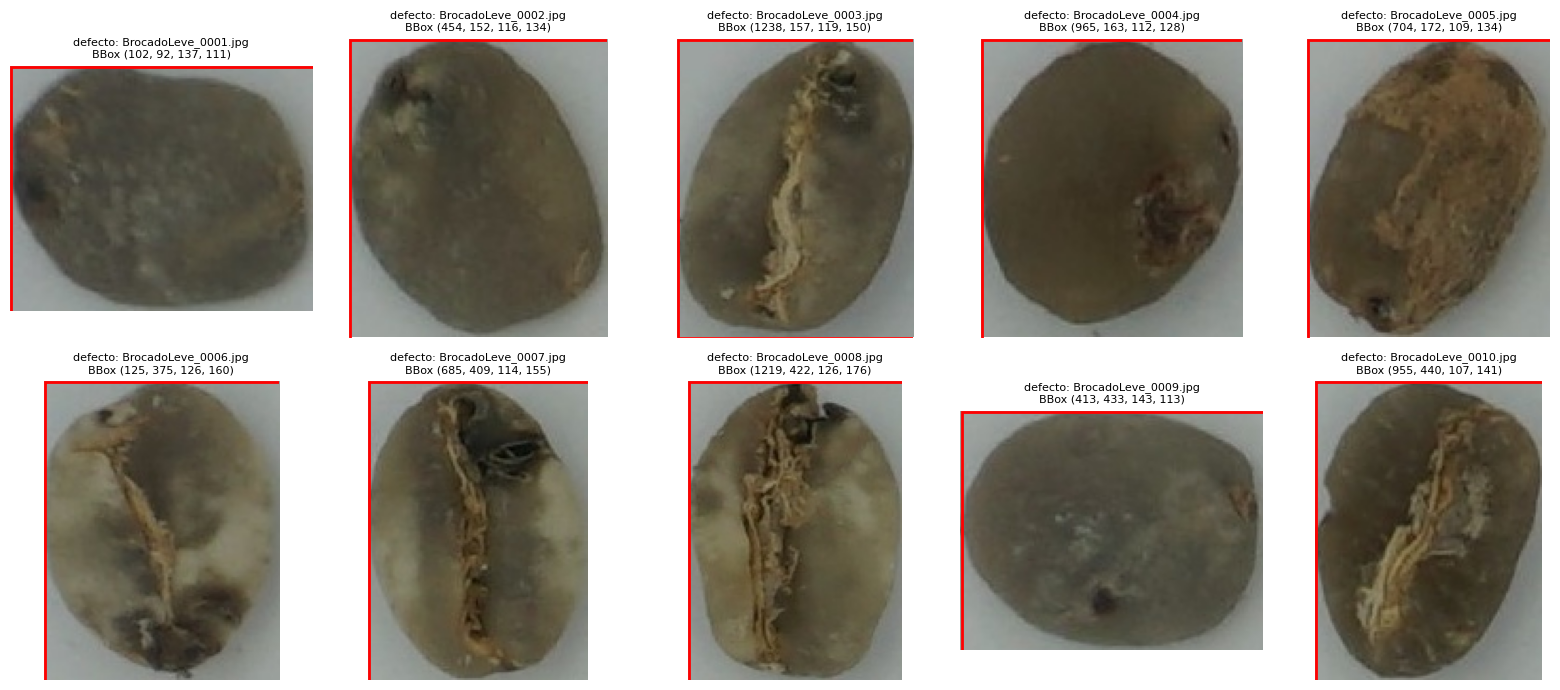

In [1]:
from pathlib import Path
import sys
import cv2
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data.extract_crops import extract_all, SOURCE_DIR
records = extract_all()
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, record in zip(axes.flat, records[:10]):
    image = cv2.imread(str(record['path']))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.add_patch(plt.Rectangle((0, 0), image.shape[1], image.shape[0], fill=False, edgecolor='red', linewidth=2))
    ax.set_title(f"{record['class']}: {record['path'].name}\nBBox {record['bbox']}", fontsize=8)
    ax.axis('off')
for ax in axes.flat[len(records[:10]):]: ax.axis('off')
plt.tight_layout()